# Mutation robustness analysis

Reads the latest `python -m mutation_analysis` run over the 1,074-candidate short list
and plots the Figure 4 / Figure 5 robustness panels.

Inputs (CSV file contracts, no module imports):

- `mutation_curves.csv` — one row per (parent, scheme, p): retention, mean P(AMP), mean σ
- `mutation_robustness.csv` — one row per (parent, scheme): parent baseline and collapsed scores

Two model outputs are used throughout, named consistently:

- **σ (sigma score)** — the **raw logit difference**, `logit_AMP − logit_nonAMP`, straight from the
  GNN head. Unbounded, signed; σ > 0 is an AMP call.
- **P(AMP)** — the **temperature-scaled probability**, `sigmoid(σ / T)`. This run used
  `fitting = "temperature"` with **T = 0.76577** (`checkpoints/gnn/gnn_vae_qsar/gnn_temperature_scaling`),
  so P ≥ 0.5 and σ > 0 select exactly the same peptides.

Δ is taken as **mutant − original**, so tolerant peptides sit near 0 and fragile ones go negative.

In [58]:
from __future__ import annotations

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for path in (here, *here.parents):
        if (path / "mutation_analysis").is_dir():
            return path
    raise FileNotFoundError("Could not locate the repository root.")


def latest_run_csv(data_root: Path, filename: str) -> Path:
    results_root = data_root / "results"
    candidates = list((results_root / "runs").glob(f"*/{filename}"))
    if not candidates:
        return results_root / filename
    return max(candidates, key=lambda path: path.stat().st_mtime_ns)


ROOT = find_repo_root()
DATA_ROOT = ROOT / "data" / "proteomes" / "1k_confirmed_candidates"
CURVES_CSV = latest_run_csv(DATA_ROOT, "mutation_curves.csv")
ROBUSTNESS_CSV = latest_run_csv(DATA_ROOT, "mutation_robustness.csv")

SCHEME_ORDER = ["physicochemical", "blosum62", "uniform"]
SCHEME_LABEL = {
    "physicochemical": "Physicochemical-preserving",
    "blosum62": "BLOSUM62-softmax",
    "uniform": "Uniform random",
}
SCHEME_COLOR = {"physicochemical": "#2a78d6", "blosum62": "#eb6834", "uniform": "#1baf7a"}
SCHEME_MARKER = {"physicochemical": "o", "blosum62": "s", "uniform": "^"}

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.family"] = "monospace"
# TrueType (Type 42) so PDF text stays editable vectors instead of raster outlines.
plt.rcParams["pdf.fonttype"] = 42

SPINE_COLOR = "#2b2b2b"
LABEL_SIZE = 10.5
TITLE_SIZE = 12


def style_axes(ax, grid_axis: str = "y") -> None:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(SPINE_COLOR)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.grid(axis=grid_axis, linestyle="--", linewidth=0.6, alpha=0.5, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", labelsize=8.5, length=3.5, width=0.8, colors=SPINE_COLOR)


print("Curves:     ", CURVES_CSV)
print("Robustness: ", ROBUSTNESS_CSV)

Curves:      /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-04_23-15/mutation_curves.csv
Robustness:  /mnt/c/Users/bioin/Documents/Peptide-Anti-microbial-Properties-Prediction/data/proteomes/1k_confirmed_candidates/results/runs/2026-11-04_23-15/mutation_robustness.csv


In [59]:
curves = pd.read_csv(CURVES_CSV)
robustness = pd.read_csv(ROBUSTNESS_CSV)

# Project vocabulary is sigma, not margin. The source CSVs still carry the
# margin_* / logit_margin names written by mutation_analysis.
SIGMA_RENAMES = {
    "parent_logit_margin": "parent_sigma",
    "margin_auc": "mutation_sigma_auc",
    "margin_slope": "sigma_slope",
    "mean_logit_margin": "mean_sigma",
    "sd_logit_margin": "sd_sigma",
    "logit_margin": "sigma",
}
curves = curves.rename(columns=SIGMA_RENAMES)
robustness = robustness.rename(columns=SIGMA_RENAMES)

PARENT_COLUMNS = ["parent_id", "length", "parent_pred", "parent_prob_AMP", "parent_sigma"]
parents = robustness[PARENT_COLUMNS].drop_duplicates("parent_id")

curves = curves.merge(parents, on="parent_id", how="left")
curves["delta_sigma"] = curves["mean_sigma"] - curves["parent_sigma"]
curves["delta_prob_AMP"] = curves["mean_delta_prob_AMP"]

# Figures restrict to candidates the model already calls AMP: sigma > 0.
amp_parents = parents[parents["parent_sigma"] > 0]
amp_curves = curves[curves["parent_id"].isin(amp_parents["parent_id"])]

P_LEVELS = sorted(curves["p"].unique())

print(f"parents:     {len(parents):,}   sigma > 0: {len(amp_parents):,}")
print(f"curve rows:  {len(curves):,}   AMP-only: {len(amp_curves):,}")
print(f"p levels:    {P_LEVELS}")
print(f"schemes:     {sorted(curves['scheme'].unique())}")
robustness.head()

parents:     1,074   sigma > 0: 578
curve rows:  28,998   AMP-only: 15,606
p levels:    [np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.25), np.float64(0.3), np.float64(0.35), np.float64(0.4), np.float64(0.45), np.float64(0.5)]
schemes:     ['blosum62', 'physicochemical', 'uniform']


,run_id,parent_id,scheme,backbone,sequence,length,parent_pred,parent_prob_AMP,parent_sigma,n_variants,...,mean_k_requested,mean_k_applied,retention_auc,retention_first_p,retention_last_p,p50_retention,mean_prob_AMP,mean_delta_prob_AMP,mutation_sigma_auc,sigma_slope
0,2026-11-04_23-15,SEQ_1,blosum62,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.159750,0.174,0.122,NaN,0.265487,-0.078697,-0.999390,-1.524896
1,2026-11-04_23-15,SEQ_1,physicochemical,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.186750,0.096,0.224,NaN,0.356734,0.012551,-0.500391,-0.073009
2,2026-11-04_23-15,SEQ_1,uniform,fixed,LSLVTKKKRFWCWQRPKYQFL,21,0,0.344183,-0.493699,4500,...,6.111111,6.111111,0.300750,0.264,0.268,NaN,0.365847,0.021663,-0.545330,-0.542866
3,2026-11-04_23-15,SEQ_2,blosum62,fixed,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,4500,...,5.444444,5.444444,0.844500,0.968,0.716,NaN,0.790439,-0.187690,1.764609,-3.202314
4,2026-11-04_23-15,SEQ_2,physicochemical,fixed,RMFRGSLYKRYPSLWRRL,18,1,0.978130,2.910319,4500,...,5.444444,5.444444,0.994625,1.000,0.978,NaN,0.953262,-0.024867,2.994937,-0.052090


## Figure 4 — Δ versus p for AMP candidates (σ > 0)

One panel per mutation scheme. Faint lines are individual peptides; the bold line is the
mean across them with a 95% confidence interval. Both Δσ and ΔP(AMP) are plotted — the
spec labels the axis Δσ, but its plotted range matches the probability scale, so both are here.

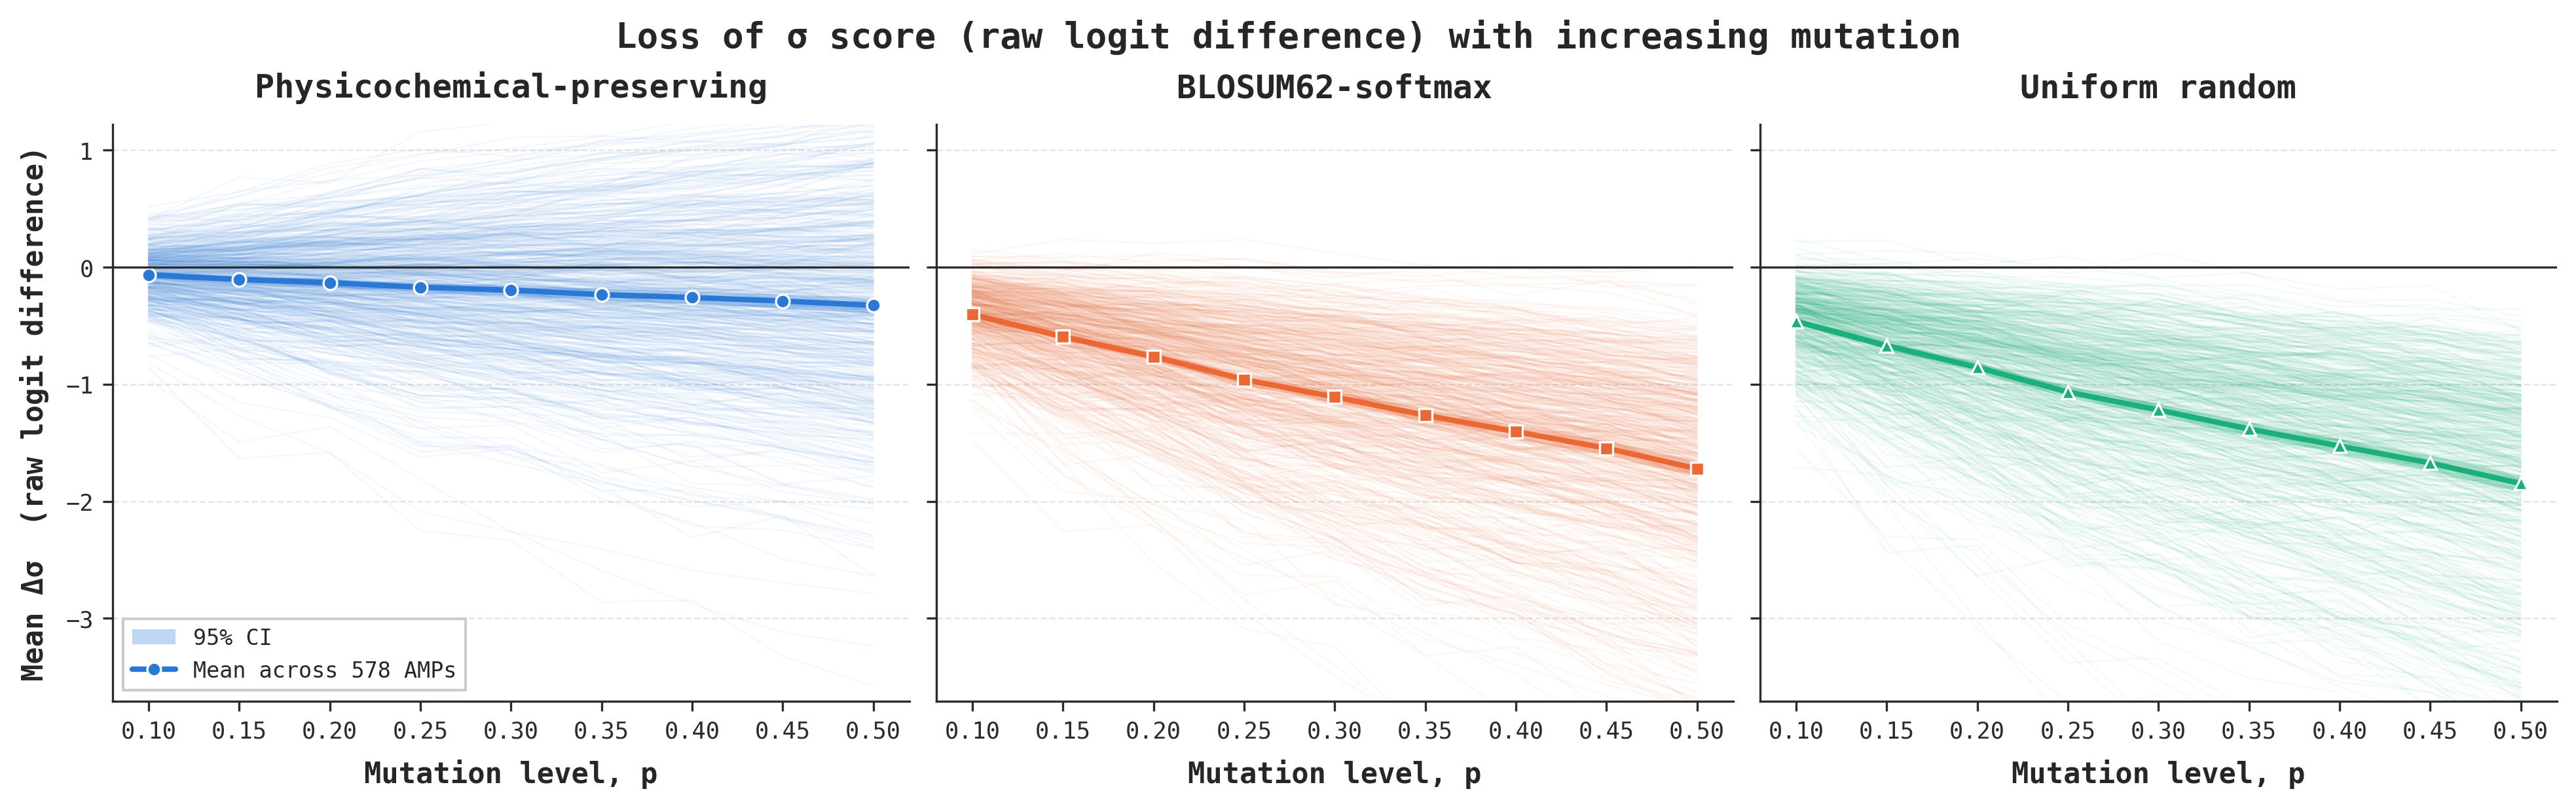

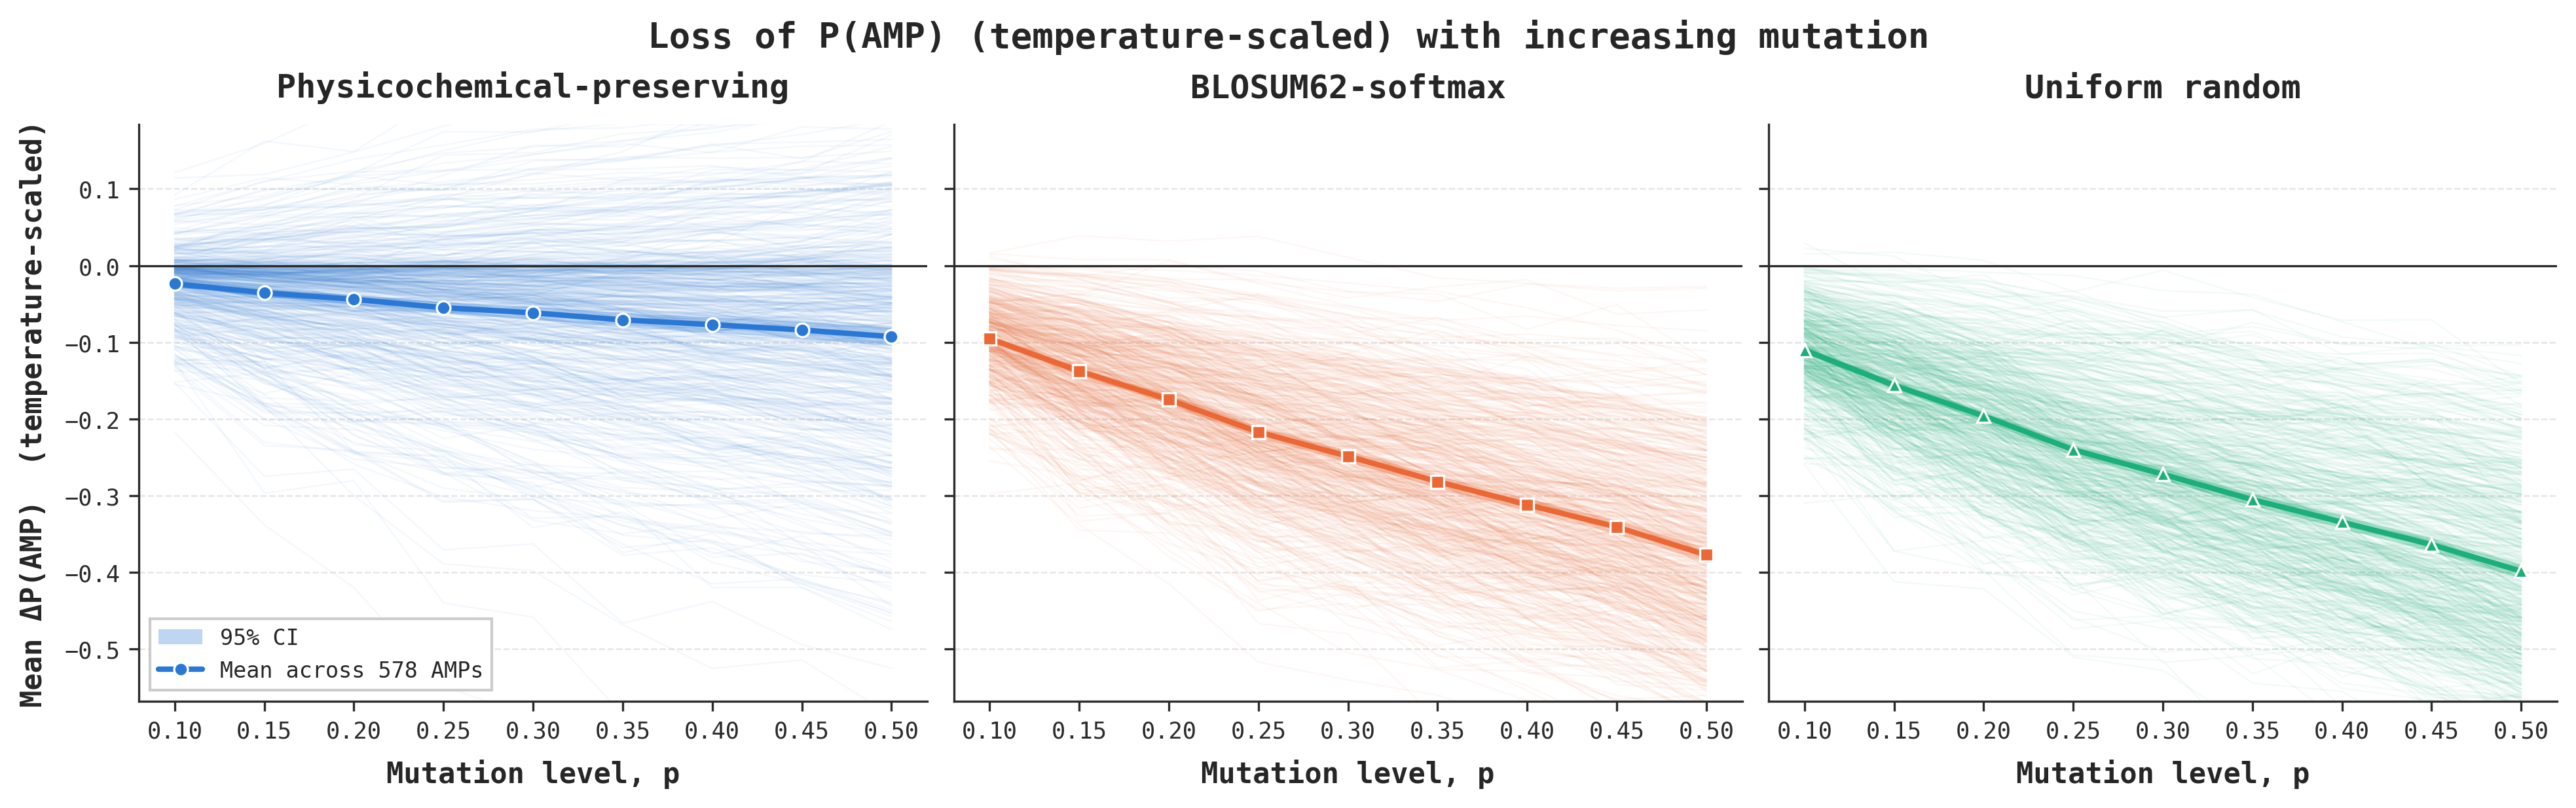

In [60]:
def mean_ci(frame: pd.DataFrame, value: str) -> pd.DataFrame:
    """Per-p mean across parents with a normal-approximation 95% CI."""
    stats = frame.groupby("p")[value].agg(["mean", "std", "count"])
    half_width = 1.96 * stats["std"] / np.sqrt(stats["count"])
    stats["low"] = stats["mean"] - half_width
    stats["high"] = stats["mean"] + half_width
    return stats.reset_index()


def plot_delta_vs_p(frame: pd.DataFrame, value: str, y_label: str, title: str) -> None:
    figure, axes = plt.subplots(1, len(SCHEME_ORDER), figsize=(13.0, 4.0), dpi=300,
                                sharey=True, layout="constrained")
    for axis, scheme in zip(axes, SCHEME_ORDER):
        subset = frame[frame["scheme"] == scheme]
        color = SCHEME_COLOR[scheme]

        spaghetti = subset.pivot(index="p", columns="parent_id", values=value)
        axis.plot(spaghetti.index, spaghetti.to_numpy(), color=color, alpha=0.05, linewidth=0.6)

        stats = mean_ci(subset, value)
        axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.3,
                          linewidth=0, label="95% CI")
        axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
                  marker=SCHEME_MARKER[scheme], markersize=5, markeredgecolor="white",
                  markeredgewidth=0.8, label=f"Mean across {subset['parent_id'].nunique():,} AMPs")

        axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
        axis.set_title(SCHEME_LABEL[scheme], fontsize=TITLE_SIZE, fontweight="bold", pad=10)
        axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
        axis.set_xticks(P_LEVELS)
        style_axes(axis)

    # Clip to the bulk so the means stay legible; a few peptides run far past this.
    low, high = np.nanpercentile(frame[value], [0.5, 99.5])
    axes[0].set_ylim(low, max(high, 0.0) + 0.05 * (high - low))
    axes[0].set_ylabel(y_label, fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
    axes[0].legend(loc="lower left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
    figure.suptitle(title, fontsize=TITLE_SIZE + 1, fontweight="bold")
    plt.show()


plot_delta_vs_p(
    amp_curves,
    "delta_sigma",
    "Mean Δσ  (raw logit difference)",
    "Loss of σ score (raw logit difference) with increasing mutation",
)
plot_delta_vs_p(
    amp_curves,
    "delta_prob_AMP",
    "Mean ΔP(AMP)  (temperature-scaled)",
    "Loss of P(AMP) (temperature-scaled) with increasing mutation",
)

## Figure 5 — retention versus p, scheme comparison

`retention` is the fraction of the 500 replicates in a cell still called AMP, so this is a
survival curve against mutation dose. The claim the figure tests: conservative substitutions
should degrade the call more slowly than uniform random ones.

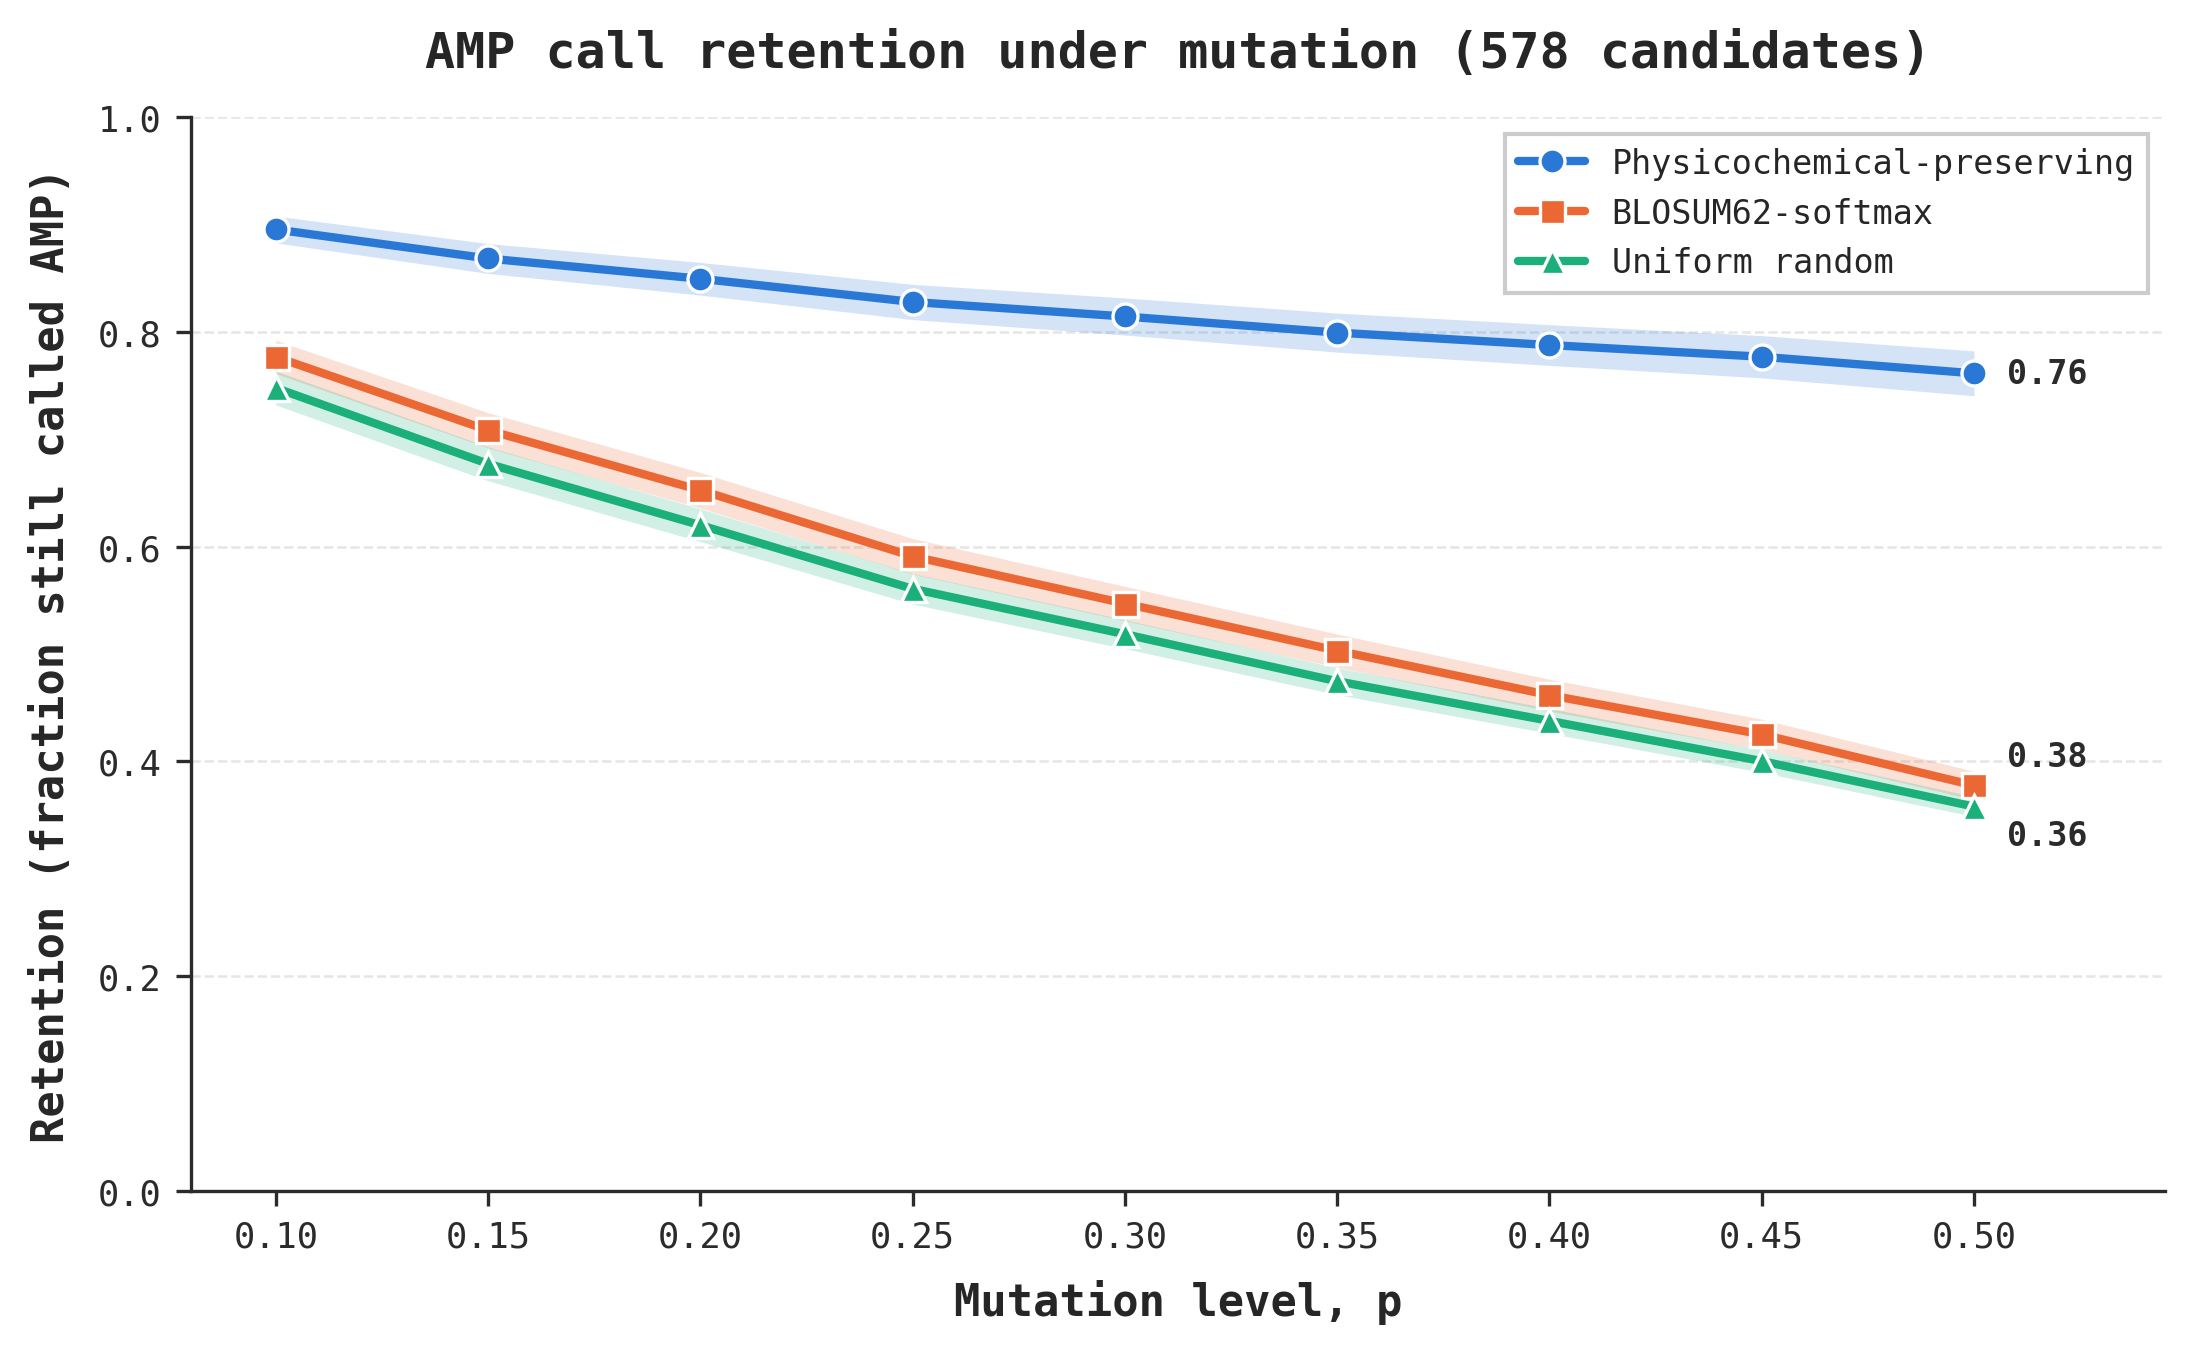

In [61]:
LABEL_OFFSET = {"physicochemical": 0.0, "blosum62": 7.0, "uniform": -7.0}

figure, axis = plt.subplots(figsize=(7.2, 4.4), dpi=300, layout="constrained")
for scheme in SCHEME_ORDER:
    stats = mean_ci(amp_curves[amp_curves["scheme"] == scheme], "retention")
    color = SCHEME_COLOR[scheme]
    axis.fill_between(stats["p"], stats["low"], stats["high"], color=color, alpha=0.2, linewidth=0)
    axis.plot(stats["p"], stats["mean"], color=color, linewidth=2.0,
              marker=SCHEME_MARKER[scheme], markersize=6, markeredgecolor="white",
              markeredgewidth=0.8, label=SCHEME_LABEL[scheme])
    axis.annotate(f"{stats['mean'].iloc[-1]:.2f}", (stats["p"].iloc[-1], stats["mean"].iloc[-1]),
                  textcoords="offset points", xytext=(8, LABEL_OFFSET[scheme]),
                  color=SPINE_COLOR, fontsize=8, fontweight="bold", va="center")

axis.set_xlabel("Mutation level, p", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Retention (fraction still called AMP)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_xticks(P_LEVELS)
axis.set_xlim(right=0.545)
axis.set_ylim(0, 1)
axis.legend(loc="upper right", fontsize=8, frameon=True, fancybox=False, framealpha=1)
axis.set_title(f"AMP call retention under mutation ({amp_curves['parent_id'].nunique():,} candidates)",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
style_axes(axis)
plt.show()

## Paper-confirmed candidates

The ten peptides below are the candidates the paper selected, labelled by gene name on every
panel in this section. Peptides from the same source protein are kept — no protein-level collapse.

Each peptide is scored by its **weakest scheme** (`min(mutation_sigma_auc)` across the three), so none can
look robust merely because physicochemical substitution barely perturbed it.

Two quantities, and the combined score that balances them:

- **σ** — `parent_sigma`, the unmutated potency.
- **σ retention** — `mutation_sigma_retained = mutation_sigma_auc / parent_sigma`, the fraction of the
  unmutated σ score still held across the sweep. Only meaningful when σ > 0; a negative σ makes the ratio flip sign, so
  it is left undefined there rather than reported as a spuriously good number.
- **combined_score** — the mean of the two percentile ranks, taken over the 578 AMP-called
  parents. Scale-free, so neither term dominates by virtue of its units. (Their straight
  *product* is just `mutation_sigma_auc` again, which is why a rank blend is used instead.)

In [62]:
PAPER_CANDIDATES = [
    ("DFNA5", "SLVTKKKRFWCWQRPKYQFL"),
    ("DCTN4", "SQLYPRHKHLLIKRSLRCRKC"),
    ("RPL41", "MRAKWRKKRMRRLK"),
    ("PSMG2", "RSIFIKYKSKPFCEKLLSWVKS"),
    ("GLB1", "SRVPRFYWKDRLLKMKMA"),
    ("RPS4X", "LPLIIFLRNRLKY"),
    ("PPP1CB", "KRRFNIKLWKTF"),
    ("CHMP2A", "RRYVRKFVLMR"),
    ("ETS1", "SRGLRYYYDKNIIHKTAGKRYVYRFV"),
    ("RPS29", "GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNM"),
]

annotations = pd.read_csv(DATA_ROOT / "sequences.csv")


def score_peptides(frame: pd.DataFrame) -> pd.DataFrame:
    """Worst-scheme score per peptide, with the sigma/retention rank blend."""
    annotated = frame.merge(
        annotations[["id", "gene_names", "leading_razor_protein"]],
        left_on="parent_id", right_on="id", how="left",
    )
    worst = annotated.loc[annotated.groupby("parent_id")["mutation_sigma_auc"].idxmin()].copy()
    worst["gene"] = worst["gene_names"].str.split(";").str[0]
    # The ratio only means anything above the decision boundary.
    is_amp = worst["parent_sigma"] > 0
    worst["mutation_sigma_retained"] = np.where(
        is_amp, worst["mutation_sigma_auc"] / worst["parent_sigma"], np.nan
    )
    worst["combined_score"] = np.nan
    worst.loc[is_amp, "combined_score"] = (
        worst.loc[is_amp, "parent_sigma"].rank(pct=True)
        + worst.loc[is_amp, "mutation_sigma_retained"].rank(pct=True)
    ) / 2
    return worst.reset_index(drop=True)


scored = score_peptides(robustness)
selected = scored[scored["sequence"].isin([sequence for _, sequence in PAPER_CANDIDATES])].copy()
selected = selected.sort_values("combined_score", ascending=False, na_position="last")
selected["rank"] = np.arange(1, len(selected) + 1)
selected["called_AMP"] = np.where(selected["parent_sigma"] > 0, "yes", "NO")

missing = {gene for gene, _ in PAPER_CANDIDATES} - set(selected["gene"])
print(f"paper-confirmed candidates matched: {len(selected)}/{len(PAPER_CANDIDATES)}"
      + (f"  MISSING: {sorted(missing)}" if missing else ""))
print(f"scored against {int((scored['parent_sigma'] > 0).sum()):,} AMP-called parents "
      f"of {len(scored):,}")

SELECTION_COLUMNS = ["rank", "gene", "parent_id", "length", "called_AMP",
                     "parent_sigma", "mutation_sigma_retained", "mutation_sigma_auc",
                     "retention_auc", "combined_score", "scheme"]
display(selected[SELECTION_COLUMNS].style.format({
    "parent_sigma": "{:.3f}", "mutation_sigma_retained": "{:.3f}", "mutation_sigma_auc": "{:.3f}",
    "retention_auc": "{:.3f}", "combined_score": "{:.3f}",
}, na_rep="—").hide(axis="index"))

paper-confirmed candidates matched: 10/10
scored against 578 AMP-called parents of 1,074


rank,gene,parent_id,length,called_AMP,parent_sigma,mutation_sigma_retained,mutation_sigma_auc,retention_auc,combined_score,scheme
1,DCTN4,SEQ_5,21,yes,5.061,0.546,2.766,0.937,0.989,uniform
2,RPS29,SEQ_18,37,yes,3.809,0.557,2.120,0.904,0.972,uniform
3,RPL41,SEQ_6,14,yes,2.460,0.637,1.567,0.816,0.908,uniform
4,ETS1,SEQ_16,26,yes,1.778,0.438,0.779,0.660,0.816,uniform
5,CHMP2A,SEQ_15,11,yes,2.078,0.124,0.258,0.563,0.657,uniform
6,PSMG2,SEQ_11,22,yes,1.501,0.252,0.378,0.577,0.649,uniform
7,GLB1,SEQ_12,18,yes,1.037,0.014,0.015,0.475,0.442,uniform
8,DFNA5,SEQ_3,20,yes,0.278,-1.102,-0.307,0.397,0.151,blosum62
9,RPS4X,SEQ_13,13,yes,0.352,-1.855,-0.653,0.284,0.138,blosum62
10,PPP1CB,SEQ_14,12,NO,-0.500,—,-0.494,0.325,—,uniform


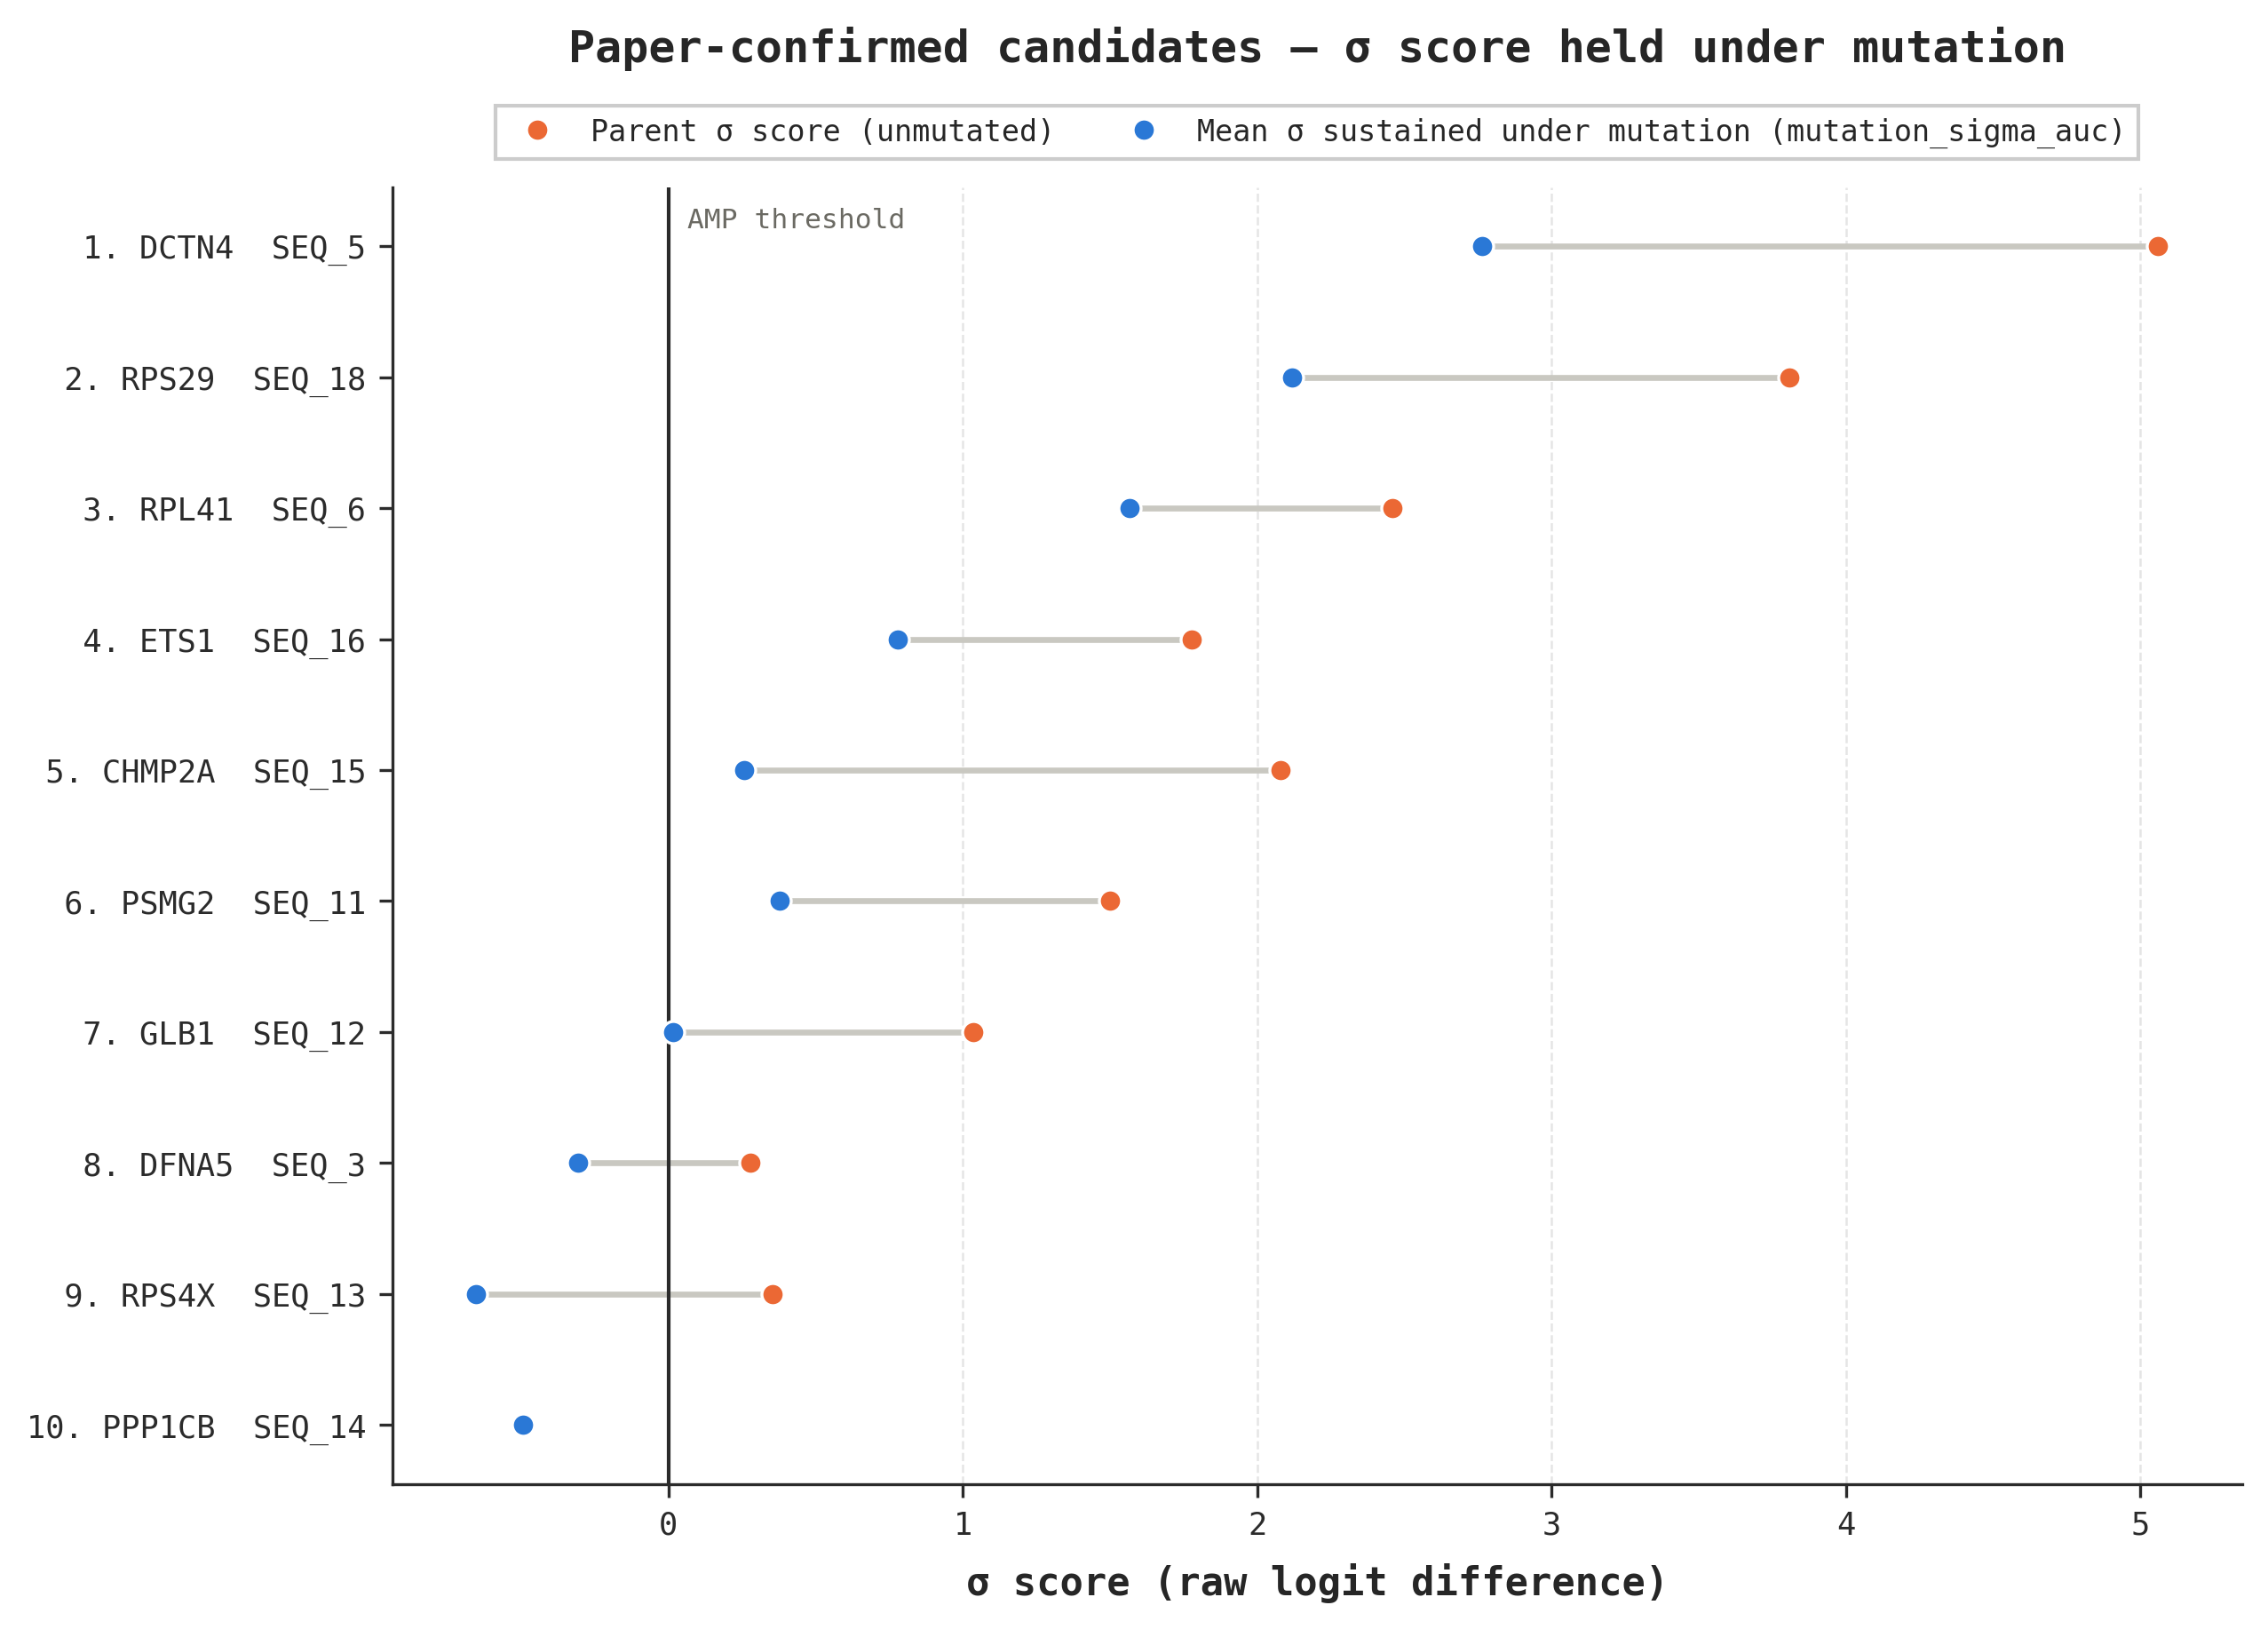

In [63]:
PARENT_COLOR = "#eb6834"
SUSTAINED_COLOR = "#2a78d6"

panel = selected.iloc[::-1]
positions = np.arange(len(panel))

figure, axis = plt.subplots(figsize=(8.4, 0.40 * len(panel) + 2.0), dpi=300, layout="constrained")
axis.hlines(positions, panel["mutation_sigma_auc"], panel["parent_sigma"],
            color="#c9c8c1", linewidth=1.6, zorder=1)
axis.plot(panel["parent_sigma"], positions, "o", markersize=6, color=PARENT_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Parent σ score (unmutated)")
axis.plot(panel["mutation_sigma_auc"], positions, "o", markersize=6, color=SUSTAINED_COLOR,
          markeredgecolor="white", markeredgewidth=0.8, zorder=3, linestyle="none",
          label="Mean σ sustained under mutation (mutation_sigma_auc)")

labels = [f"{rank:>2}. {gene}  {pid}"
          for rank, gene, pid in zip(panel["rank"], panel["gene"], panel["parent_id"])]
axis.set_yticks(positions)
axis.set_yticklabels(labels)
axis.axvline(0.0, color=SPINE_COLOR, linewidth=1.0)
axis.annotate("AMP threshold", xy=(0.0, 1.0), xycoords=("data", "axes fraction"),
              textcoords="offset points", xytext=(5, -11), fontsize=7.5, color="#6b6a63")
axis.set_xlabel("σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_title("Paper-confirmed candidates — σ score held under mutation",
               fontsize=TITLE_SIZE, fontweight="bold", pad=34)
axis.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2,
            fontsize=8, frameon=True, fancybox=False, framealpha=1)
style_axes(axis, grid_axis="x")
plt.show()

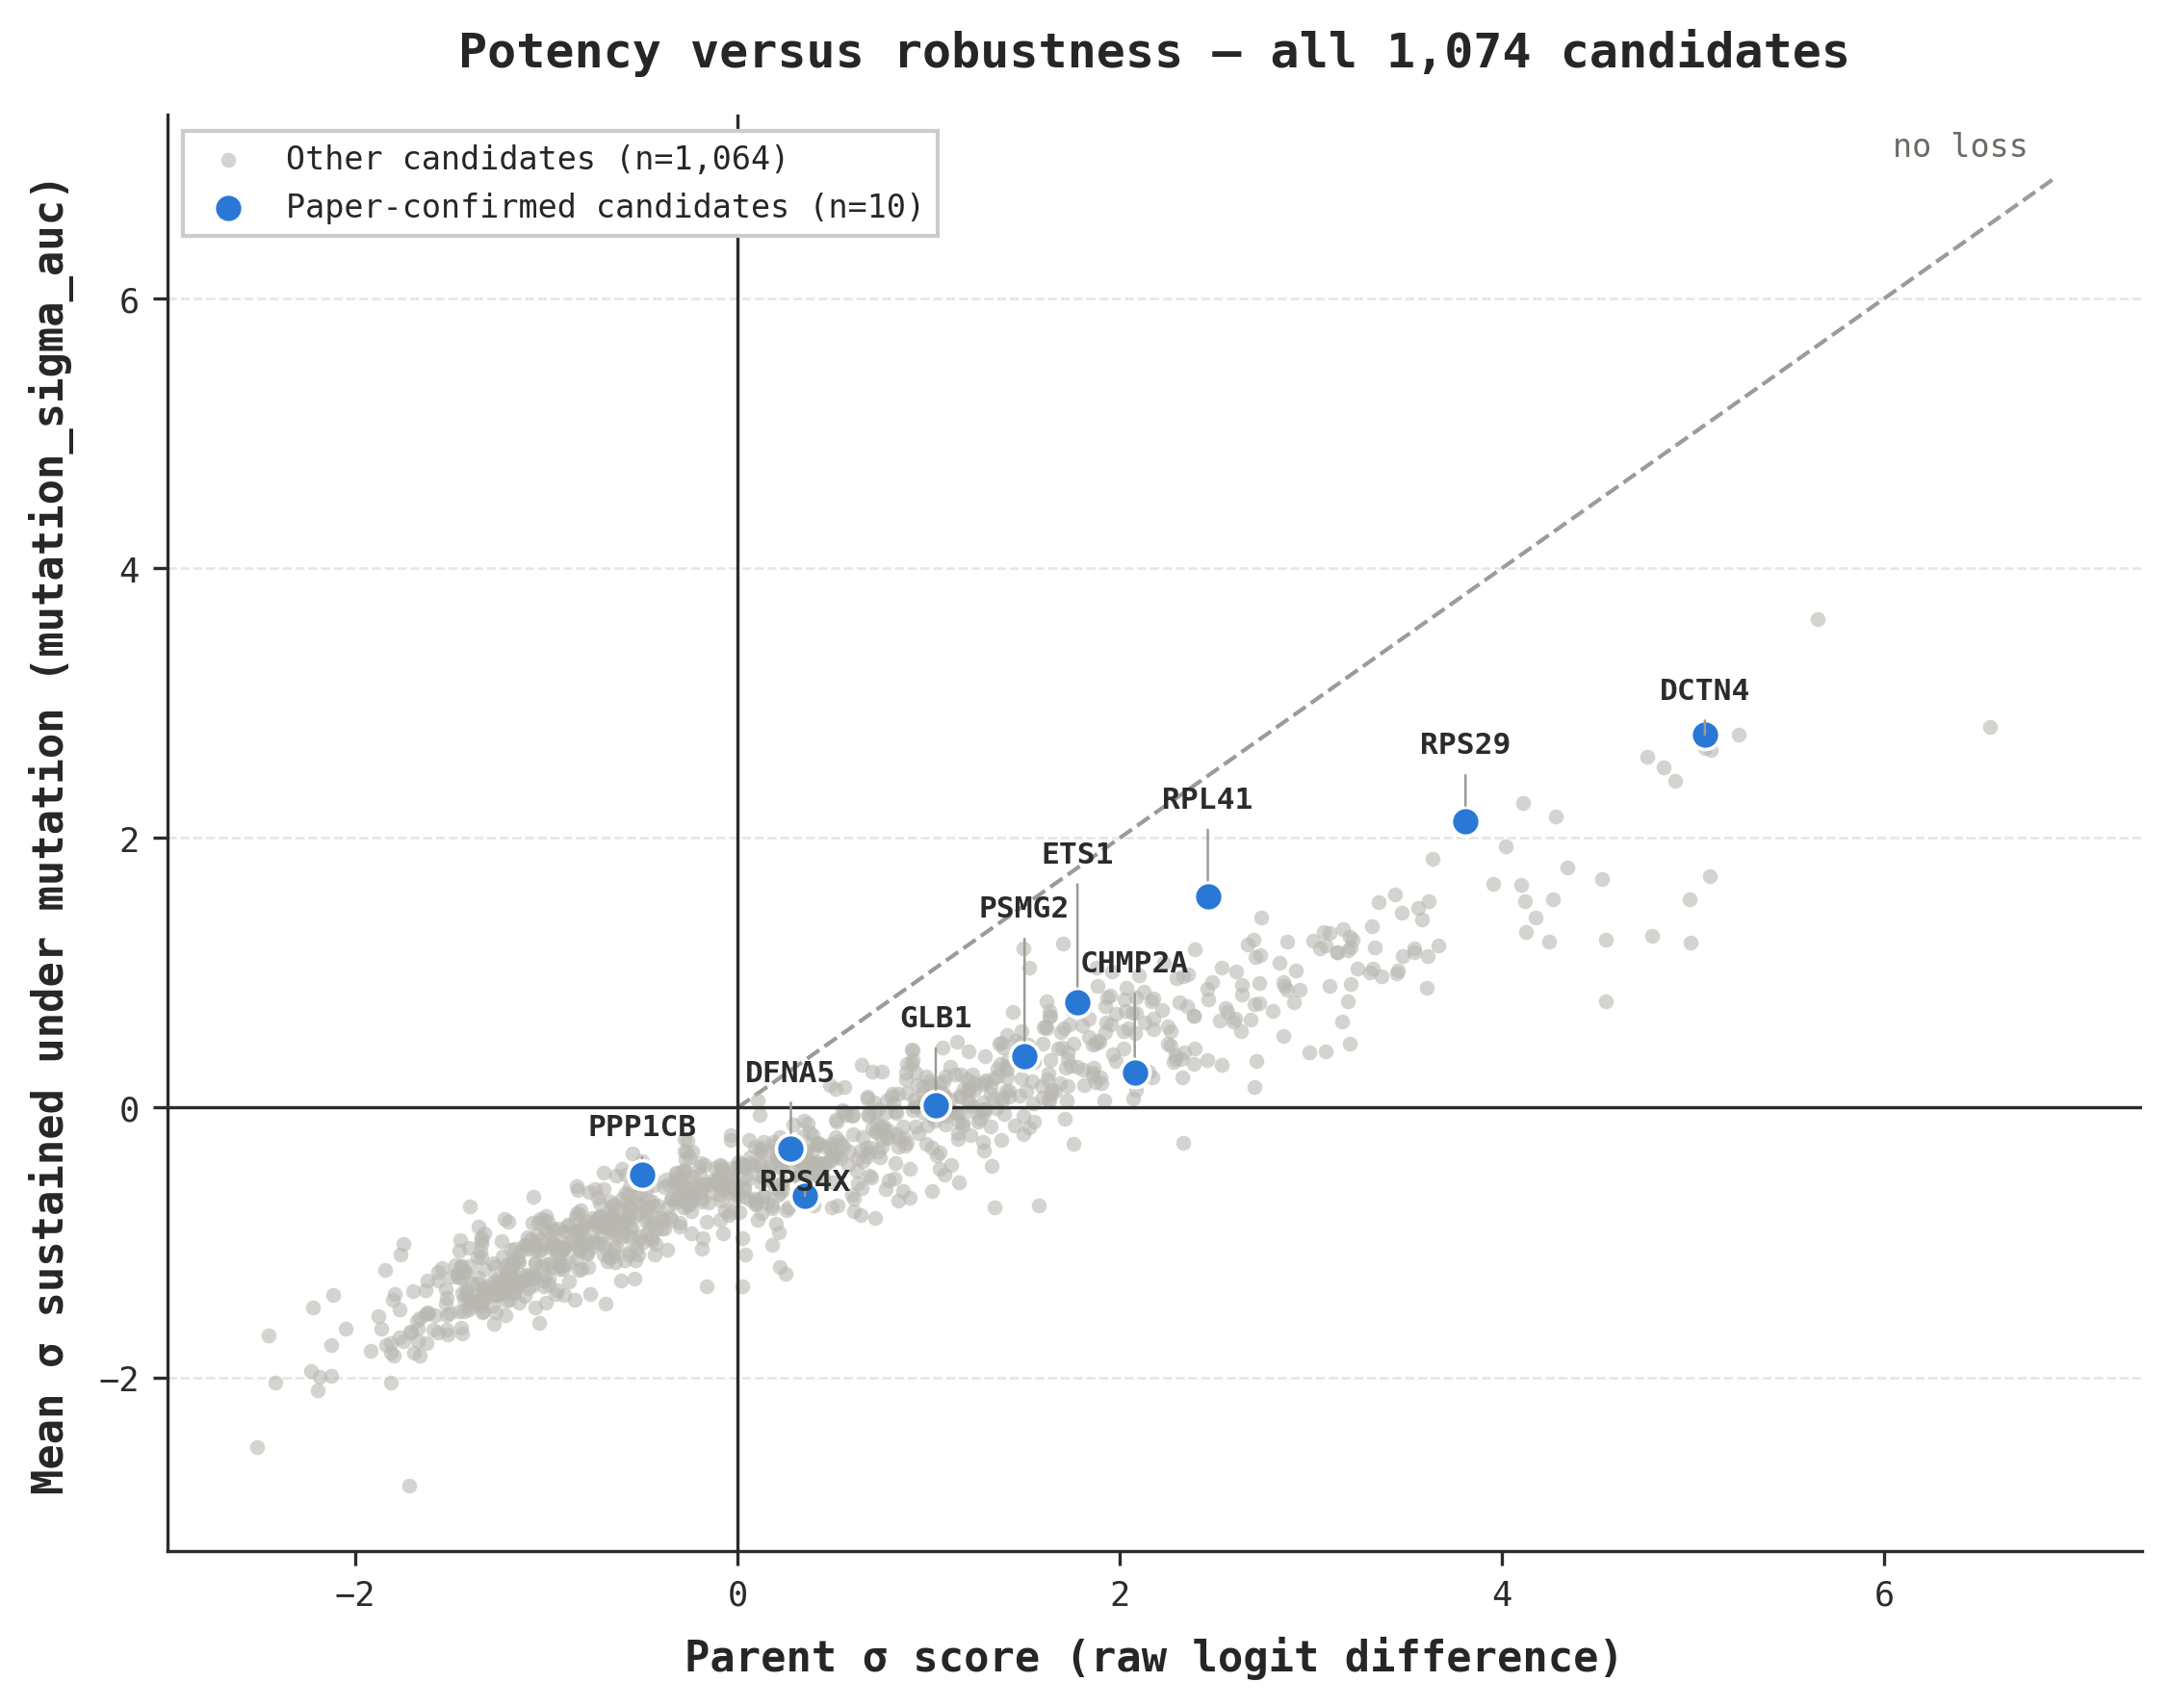

In [64]:
others = scored[~scored["parent_id"].isin(selected["parent_id"])]
limit = float(scored["parent_sigma"].max()) * 1.05

figure, axis = plt.subplots(figsize=(7.4, 5.8), dpi=300, layout="constrained")
axis.plot([0, limit], [0, limit], linestyle="--", linewidth=1.0, color="#9c9b94", zorder=1)
axis.annotate("no loss", (limit, limit), textcoords="offset points", xytext=(-6, 6),
              ha="right", fontsize=8, color="#6b6a63")
axis.scatter(others["parent_sigma"], others["mutation_sigma_auc"], s=14, color="#b8b7b0",
             alpha=0.6, linewidth=0, zorder=2, label=f"Other candidates (n={len(others):,})")
axis.scatter(selected["parent_sigma"], selected["mutation_sigma_auc"], s=52,
             color=SUSTAINED_COLOR, edgecolor="white", linewidth=0.9, zorder=3,
             label=f"Paper-confirmed candidates (n={len(selected)})")

# Seven of the ten fall in one dense clump, so gene names are spread vertically
# to a minimum gap and tied back to their marker with a leader line.
axis.set_ylim(axis.get_ylim())
y_low, y_high = axis.get_ylim()
minimum_gap = (y_high - y_low) * 0.038

ladder = selected.sort_values("mutation_sigma_auc").reset_index(drop=True)
label_heights = []
previous = -np.inf
for value in ladder["mutation_sigma_auc"]:
    previous = max(float(value), previous + minimum_gap)
    label_heights.append(previous)

for row, height in zip(ladder.itertuples(), label_heights):
    # Leader stays vertical: a straight drop to the marker is far easier to
    # trace through the cloud than a diagonal one.
    axis.annotate(
        row.gene,
        xy=(row.parent_sigma, row.mutation_sigma_auc),
        xytext=(row.parent_sigma, height),
        fontsize=7.5, fontweight="bold", color=SPINE_COLOR,
        ha="center", va="bottom", zorder=4,
        arrowprops=dict(arrowstyle="-", color="#9c9b94", linewidth=0.6,
                        shrinkA=2, shrinkB=4),
    )

axis.axhline(0.0, color=SPINE_COLOR, linewidth=0.8)
axis.axvline(0.0, color=SPINE_COLOR, linewidth=0.8)
axis.set_xlabel("Parent σ score (raw logit difference)", fontsize=LABEL_SIZE, fontweight="bold", labelpad=6)
axis.set_ylabel("Mean σ sustained under mutation (mutation_sigma_auc)", fontsize=LABEL_SIZE,
                fontweight="bold", labelpad=6)
axis.set_title("Potency versus robustness — all 1,074 candidates",
               fontsize=TITLE_SIZE, fontweight="bold", pad=12)
axis.legend(loc="upper left", fontsize=8, frameon=True, fancybox=False, framealpha=1)
style_axes(axis)
plt.show()

## Caveat — nominal `p` is not a distinct dose at short lengths

`k = floor(p·L + 0.5)`, so several nominal `p` levels collapse onto the same substitution
count for short peptides. Those cells re-measure a dose already measured, which shows up as a
stair-step in the curves above and makes `retention_auc` weight doses unevenly in a way that
varies with length. The table below quantifies it for the loaded run.

In [65]:
redundancy = curves.copy()
redundancy["duplicate_k"] = redundancy.duplicated(["parent_id", "scheme", "k_requested"])
by_length = redundancy.groupby("length").agg(
    cells=("duplicate_k", "size"),
    redundant=("duplicate_k", "sum"),
)
by_length["fraction"] = (by_length["redundant"] / by_length["cells"]).round(3)

overall = redundancy["duplicate_k"].mean()
print(f"redundant cells: {redundancy['duplicate_k'].sum():,} / {len(redundancy):,} ({overall:.1%})")
print(f"variants spent re-measuring a known dose: {redundancy.loc[redundancy['duplicate_k'], 'n_variants'].sum():,}")
by_length.head(12)

redundant cells: 2,982 / 28,998 (10.3%)
variants spent re-measuring a known dose: 1,491,000


,cells,redundant,fraction
length,,,
8,81,45,0.556
9,162,72,0.444
10,378,168,0.444
11,945,315,0.333
12,1350,450,0.333
13,1323,294,0.222
14,1836,408,0.222
15,1728,384,0.222
16,1809,402,0.222


## Top 20 peptides by sustained σ (`mutation_sigma_auc`)

The whole candidate set ranked by **`mutation_sigma_auc`** — the mean σ score sustained across the
mutation sweep, in raw logit units. No weighting choice enters it: `mutation_sigma_auc` is already
`parent σ × mutation_sigma_retained`, a product rather than a blend.

`mutation_sigma_retained = mutation_sigma_auc / parent σ` is reported beside it as the descriptor — the
fraction of the unmutated σ score still held. Peptides are **not** collapsed by source protein,
so overlapping windows of one protein each hold their own row.

In [66]:
TOP_N = 20

leaderboard = scored.nlargest(TOP_N, "mutation_sigma_auc").copy()
leaderboard["rank"] = np.arange(1, len(leaderboard) + 1)
print(f"top {TOP_N} peptides span {leaderboard['leading_razor_protein'].nunique()} distinct "
      f"protein(s); most frequent: "
      f"{leaderboard['gene'].value_counts().index[0]} x{leaderboard['gene'].value_counts().iloc[0]}")
# Exact, case-sensitive sequence equality - not a substring or normalised match.
paper_sequences = {sequence for _, sequence in PAPER_CANDIDATES}
leaderboard["paper_candidate"] = np.where(
    leaderboard["sequence"].isin(paper_sequences), "yes", "no"
)
print(f"overlap with the paper's ten: "
      f"{int((leaderboard['paper_candidate'] == 'yes').sum())}/{len(PAPER_CANDIDATES)}")

LEADERBOARD_COLUMNS = ["rank", "gene", "leading_razor_protein", "sequence",
                       "paper_candidate", "parent_sigma", "mutation_sigma_auc", "mutation_sigma_retained"]
display(leaderboard[LEADERBOARD_COLUMNS].style.format({
    "parent_sigma": "{:.3f}", "mutation_sigma_auc": "{:.3f}", "mutation_sigma_retained": "{:.3f}",
}).hide(axis="index"))

top 20 peptides span 10 distinct protein(s); most frequent: RPS29 x10
overlap with the paper's ten: 2/10


rank,gene,leading_razor_protein,sequence,paper_candidate,parent_sigma,mutation_sigma_auc,mutation_sigma_retained
1,GRN,P28799,GWACCPYRQGVCCADRRHCCPAGFRCAARGTKCLR,no,5.652,3.623,0.641
2,GIT1,Q9Y2X7,HRSLGRHISIVKHLRH,no,6.552,2.821,0.431
3,RPS29,P62273,SHPRKFGQGSRSCRVCSNRHGLIRKY,no,5.238,2.768,0.528
4,DCTN4,Q9UJW0,SQLYPRHKHLLIKRSLRCRKC,yes,5.061,2.766,0.546
5,RPS29,P62273,PRKFGQGSRSCRVCSNRHGLIRKY,no,5.060,2.669,0.527
6,RPS29,P62273,YWSHPRKFGQGSRSCRVCSNRHGLIRKYGL,no,5.094,2.651,0.520
7,RPL10,P27635,GRRPARCYRYCKNKPYPKSRFC,no,4.761,2.599,0.546
8,RPS29,P62273,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGL,no,4.843,2.521,0.521
9,RPS29,P62273,YWSHPRKFGQGSRSCRVCSNRHGLIRKY,no,4.908,2.426,0.494
10,RPS29,P62273,GHQQLYWSHPRKFGQGSRSCRVCSNRHGLIRKYGLNMC,no,4.110,2.262,0.550
